<a href="https://colab.research.google.com/github/charithayadavelli/GitGitubWorkShop-26/blob/main/microfinance_analysing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

states_regions = {
    'North': ['Uttar Pradesh', 'Punjab', 'Haryana', 'Rajasthan', 'Himachal Pradesh'],
    'South': ['Tamil Nadu', 'Karnataka', 'Kerala', 'Andhra Pradesh', 'Telangana'],
    'East': ['West Bengal', 'Bihar', 'Odisha', 'Jharkhand', 'Assam'],
    'West': ['Maharashtra', 'Gujarat', 'Madhya Pradesh', 'Chhattisgarh']
}

quarters = ['2023-Q1', '2023-Q2', '2023-Q3', '2023-Q4', '2024-Q1', '2024-Q2', '2024-Q3', '2024-Q4']

rows = []
for region, state_list in states_regions.items():
    for state in state_list:
        base_borrowers = np.random.randint(150000, 600000)
        base_branches = np.random.randint(150, 600)

        for q_idx, q in enumerate(quarters):
            growth_factor = 1 + (q_idx * 0.03) + np.random.uniform(-0.02, 0.04)
            borrowers = int(base_borrowers * growth_factor)
            avg_loan_inr = np.random.uniform(12000, 18000)
            loan_disbursed_cr = round((borrowers * avg_loan_inr) / 10000000, 2)
            branches = int(base_branches * (1 + q_idx * 0.01))

            rows.append({
                'State': state,
                'Zone': region,
                'Reporting_Period': q,
                'Active_Borrowers': borrowers,
                'Loan_Amount_Disbursed_Cr': loan_disbursed_cr,
                'Branches': branches
            })

df_large = pd.DataFrame(rows)
print(f"Large dataset created successfully! Total rows: {len(df_large)}")
display(df_large.head())

Large dataset created successfully! Total rows: 152


,State,Zone,Reporting_Period,Active_Borrowers,Loan_Amount_Disbursed_Cr,Branches
0,Uttar Pradesh,North,2023-Q1,282032,462.31,585
1,Uttar Pradesh,North,2023-Q2,284446,367.96,590
2,Uttar Pradesh,North,2023-Q3,285381,352.40,596
3,Uttar Pradesh,North,2023-Q4,305128,476.20,602
4,Uttar Pradesh,North,2024-Q1,310707,376.69,608


In [5]:
import pandas as pd

total_disbursed = df_large['Loan_Amount_Disbursed_Cr'].sum()
total_borrowers = df_large['Active_Borrowers'].sum()
avg_loan_per_borrower = (total_disbursed * 10000000) / total_borrowers

print(f"Total Disbursement (2023-2024): ₹ {total_disbursed:,.2f} Crores")
print(f"Total Cumulative Active Borrower Counts: {total_borrowers:,}")
print(f"Overall Average Loan Size: ₹ {avg_loan_per_borrower:,.2f}")

zone_summary = df_large.groupby('Zone')[['Active_Borrowers', 'Loan_Amount_Disbursed_Cr', 'Branches']].sum().reset_index()

print("\n--- Summary by Zone ---")
display(zone_summary)

Total Disbursement (2023-2024): ₹ 98,089.48 Crores
Total Cumulative Active Borrower Counts: 66,070,147
Overall Average Loan Size: ₹ 14,846.26

--- Summary by Zone ---


,Zone,Active_Borrowers,Loan_Amount_Disbursed_Cr,Branches
0,East,21907692,33919.94,14186
1,North,15933777,23367.60,16024
2,South,12092656,17648.85,15023
3,West,16136022,23153.09,9884


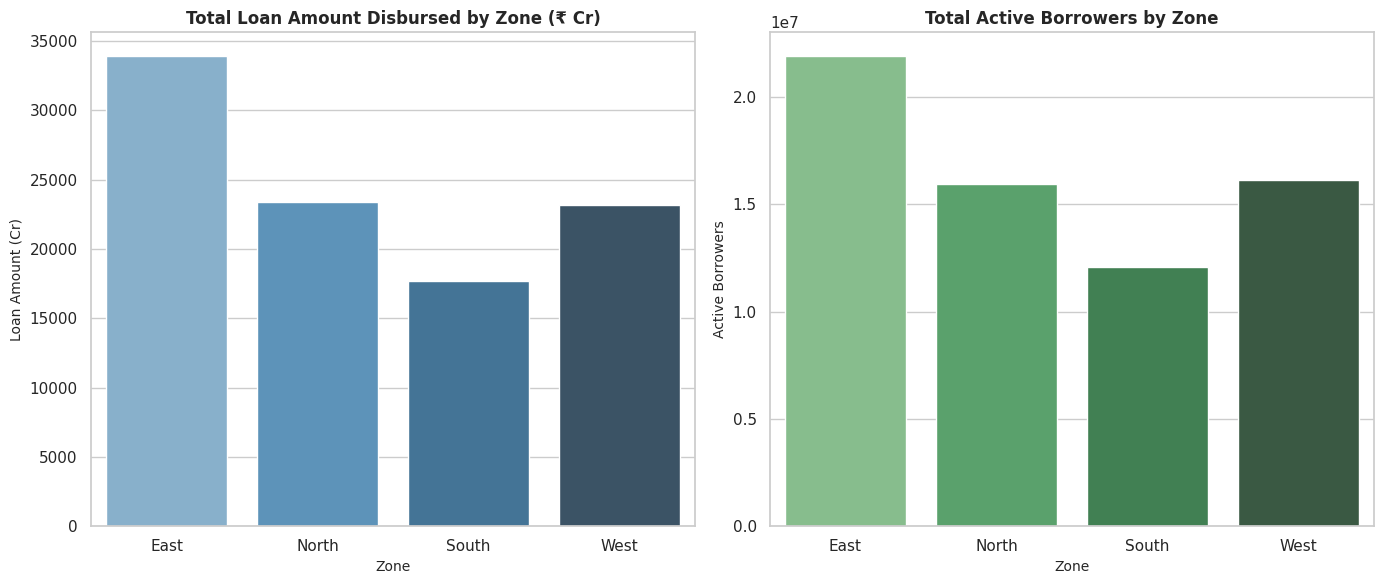

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    data=zone_summary,
    x='Zone',
    y='Loan_Amount_Disbursed_Cr',
    ax=axes[0],
    palette='Blues_d',
    hue='Zone',
    legend=False
)
axes[0].set_title('Total Loan Amount Disbursed by Zone (₹ Cr)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Zone', fontsize=10)
axes[0].set_ylabel('Loan Amount (Cr)', fontsize=10)

sns.barplot(
    data=zone_summary,
    x='Zone',
    y='Active_Borrowers',
    ax=axes[1],
    palette='Greens_d',
    hue='Zone',
    legend=False
)
axes[1].set_title('Total Active Borrowers by Zone', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Zone', fontsize=10)
axes[1].set_ylabel('Active Borrowers', fontsize=10)

plt.tight_layout()
plt.show()

[Success] Large dataset saved as 'large_microfinance_dataset.csv'!


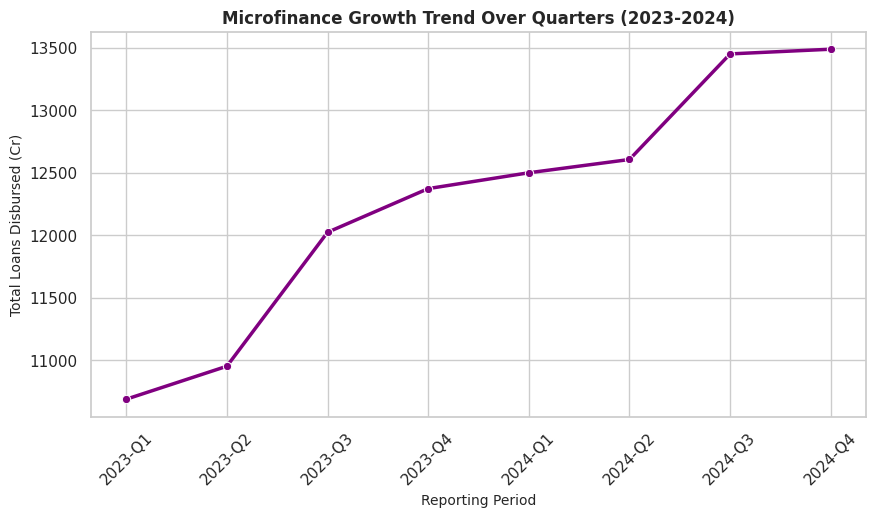

[Success] Trend chart saved as 'large_dataset_trend.png'!


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

df_large.to_csv('large_microfinance_dataset.csv', index=False)
print("[Success] Large dataset saved as 'large_microfinance_dataset.csv'!")

plt.figure(figsize=(10, 5))
quarterly_trend = df_large.groupby('Reporting_Period')['Loan_Amount_Disbursed_Cr'].sum().reset_index()
sns.lineplot(data=quarterly_trend, x='Reporting_Period', y='Loan_Amount_Disbursed_Cr', marker='o', color='purple', linewidth=2.5)
plt.title('Microfinance Growth Trend Over Quarters (2023-2024)', fontsize=12, fontweight='bold')
plt.xlabel('Reporting Period', fontsize=10)
plt.ylabel('Total Loans Disbursed (Cr)', fontsize=10)
plt.xticks(rotation=45)
plt.grid(True)
plt.savefig('large_dataset_trend.png', dpi=300, bbox_inches='tight')
plt.show()

print("[Success] Trend chart saved as 'large_dataset_trend.png'!")